# 07 · Ablación por grupos de variables e importancia por permutación

**Pregunta:** ¿qué factores sostienen la predicción y, en particular, cuánto aporta la lluvia?

Dos medidas complementarias, con el mejor modelo individual de cada variable objetivo (configuración ajustada
en 03 y 04):

| Variable objetivo | Modelo | Métrica |
|---|---|---|
| `N_ACC` | Gradient boosting (Poisson) | D² de Poisson |
| `HAY_FATAL` | Random Forest | PR-AUC |
| `GRAVEDAD` | Random Forest | Macro-F1 |

- **Ablación:** se reentrena el modelo sin un grupo (`M.columnas(grupos, sin=[g])`) y se mide cuánto cae la métrica
  en la misma validación del baseline (5 pliegues temporales en la Tarea 1; CV estratificada 5×5 en la Tarea 2).
  Mide lo que el modelo **pierde** si no tiene el grupo: si otro grupo lleva la misma información, la caída es pequeña.
- **Permutación:** con el modelo entrenado en todo el train, se desordenan juntas las columnas de un grupo en el
  holdout/test (10 repeticiones) y se mide la caída. Mide cuánto **usa** el modelo ese grupo.

El ensamble no se incluye: reentrenarlo por pliegue y por grupo (con el MLP) multiplica el tiempo sin cambiar la pregunta.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import models as M, evaluation as E

warnings.filterwarnings("ignore")
PLOTS = ROOT / "results" / "plots"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
t0 = time.time()


def ablacion(fabrica, grupos, X, y, folds, metricas, principal, proba=False):
    """Métrica con todos los grupos frente a la métrica sin cada grupo, pliegue a pliegue (mismos pliegues)."""
    folds = list(folds)
    completo = E.cv_puntajes(fabrica(M.columnas(grupos)), X, y, folds, metricas, proba)
    filas = []
    for g in grupos:
        sin_g = E.cv_puntajes(fabrica(M.columnas(grupos, sin=[g])), X, y, folds, metricas, proba)
        d = completo[principal] - sin_g[principal]          # > 0: el modelo empeora sin el grupo
        filas.append(dict(grupo=g, completo=completo[principal].mean(), sin_grupo=sin_g[principal].mean(),
                          caida=d.mean(), ic95=1.96 * d.std(ddof=1) / np.sqrt(len(d)),
                          pliegues_peor=f"{(d > 0).sum()} de {len(d)}"))
    return pd.DataFrame(filas).sort_values("caida", ascending=False).reset_index(drop=True)


def permutacion_grupos(modelo, grupos, X, y, puntaje, n_rep=10, seed=M.SEED):
    """Caída de la métrica al desordenar juntas todas las columnas de un grupo (misma permutación de filas)."""
    rng = np.random.default_rng(seed)
    base = puntaje(y, modelo, X)
    filas = []
    for g, (num, cat) in grupos.items():
        cols = num + cat
        caidas = []
        for _ in range(n_rep):
            Xp = X.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
            caidas.append(base - puntaje(y, modelo, Xp))
        filas.append(dict(grupo=g, caida=np.mean(caidas), desv=np.std(caidas)))
    return pd.DataFrame(filas).sort_values("caida", ascending=False).reset_index(drop=True)


def grafico(ax, tabla, titulo, xlabel):
    t = tabla.iloc[::-1]
    colores = ["#2b6cb0" if g == "clima" else "#9aa5b1" for g in t.grupo]   # clima resaltado: es la pregunta
    err = t["ic95"] if "ic95" in t else t["desv"]
    ax.barh(t.grupo, t.caida, xerr=err, color=colores)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel)


# Configuraciones elegidas en 03_random_forest.ipynb y 04_gradient_boosting.ipynb (las mismas de 06_mlp.ipynb).
RF_AJ = {"HAY_FATAL": dict(class_weight=None, min_samples_leaf=40, max_features=0.35, max_depth=8),
         "GRAVEDAD": dict(class_weight="balanced_subsample", min_samples_leaf=3, max_features="sqrt", max_depth=12)}
GBM_AJ = {"N_ACC": dict(learning_rate=0.03, max_iter=100, max_leaf_nodes=7, min_samples_leaf=100, l2_regularization=1.0)}

## 1. Datos y validación (los mismos del baseline)

In [2]:
panel = M.cargar_panel()
tr1 = panel[panel.FECHA < M.INICIO_HOLDOUT].reset_index(drop=True)
te1 = panel[panel.FECHA >= M.INICIO_HOLDOUT].reset_index(drop=True)
COLS1 = M.columnas(M.GRUPOS_T1)
X1 = COLS1[0] + COLS1[1]
FOLDS1 = list(E.cv_temporal(tr1.FECHA))

acc = M.cargar_accidentes()
COLS2 = M.columnas(M.GRUPOS_T2)
X2 = COLS2[0] + COLS2[1]
tr2, te2 = train_test_split(acc, test_size=0.2, stratify=acc.GRAVEDAD, random_state=M.SEED)
FOLDS2 = list(E.CV_REPETIDA.split(tr2[X2], tr2.GRAVEDAD))
print(f"Tarea 1: train {len(tr1):,} / holdout {len(te1):,} · Tarea 2: train {len(tr2):,} / test {len(te2):,}")

Tarea 1: train 10,776 / holdout 4,392 · Tarea 2: train 6,484 / test 1,621


## 2. Ablación por grupos
`caida` = métrica con todos los grupos − métrica sin el grupo (positiva: el grupo aporta). `pliegues_peor` = en
cuántos pliegues el modelo empeora sin el grupo.

In [3]:
abl_nacc = ablacion(lambda c: M.gbm_conteo(c, **GBM_AJ["N_ACC"]), M.GRUPOS_T1, tr1[X1], tr1.N_ACC, FOLDS1,
                    E.metricas_conteo, "d2_poisson")
abl_fatal = ablacion(lambda c: M.random_forest(c, **RF_AJ["HAY_FATAL"]), M.GRUPOS_T1, tr1[X1], tr1.HAY_FATAL,
                     FOLDS1, E.metricas_binaria, "pr_auc", proba=True)
print("N_ACC · gradient boosting (D² de Poisson)"); display(abl_nacc.round(4))
print("HAY_FATAL · Random Forest (PR-AUC)"); display(abl_fatal.round(4))

N_ACC · gradient boosting (D² de Poisson)


,grupo,completo,sin_grupo,caida,ic95,pliegues_peor
0,lugar,0.2668,0.2450,0.0218,0.0066,5 de 5
1,calendario,0.2668,0.2613,0.0055,0.0046,4 de 5
2,clima,0.2668,0.2656,0.0012,0.0010,4 de 5
3,historia,0.2668,0.2676,-0.0008,0.0097,3 de 5


HAY_FATAL · Random Forest (PR-AUC)


,grupo,completo,sin_grupo,caida,ic95,pliegues_peor
0,lugar,0.1395,0.1351,0.0045,0.0048,5 de 5
1,calendario,0.1395,0.1374,0.0021,0.0033,4 de 5
2,clima,0.1395,0.1395,0.0000,0.0044,2 de 5
3,historia,0.1395,0.1426,-0.0031,0.0217,2 de 5


In [4]:
abl_grav = ablacion(lambda c: M.random_forest(c, **RF_AJ["GRAVEDAD"]), M.GRUPOS_T2, tr2[X2], tr2.GRAVEDAD, FOLDS2,
                    E.metricas_multiclase, "macro_f1", proba=True)
print("GRAVEDAD · Random Forest (macro-F1)"); display(abl_grav.round(4))

GRAVEDAD · Random Forest (macro-F1)


,grupo,completo,sin_grupo,caida,ic95,pliegues_peor
0,tipo de choque,0.4537,0.4108,0.0428,0.0043,25 de 25
1,lugar,0.4537,0.4396,0.0140,0.0035,22 de 25
2,luz y hora,0.4537,0.4406,0.0131,0.0034,24 de 25
3,vía,0.4537,0.4509,0.0028,0.0034,13 de 25
4,clima,0.4537,0.4513,0.0024,0.0034,15 de 25
5,calendario,0.4537,0.4520,0.0017,0.0029,17 de 25


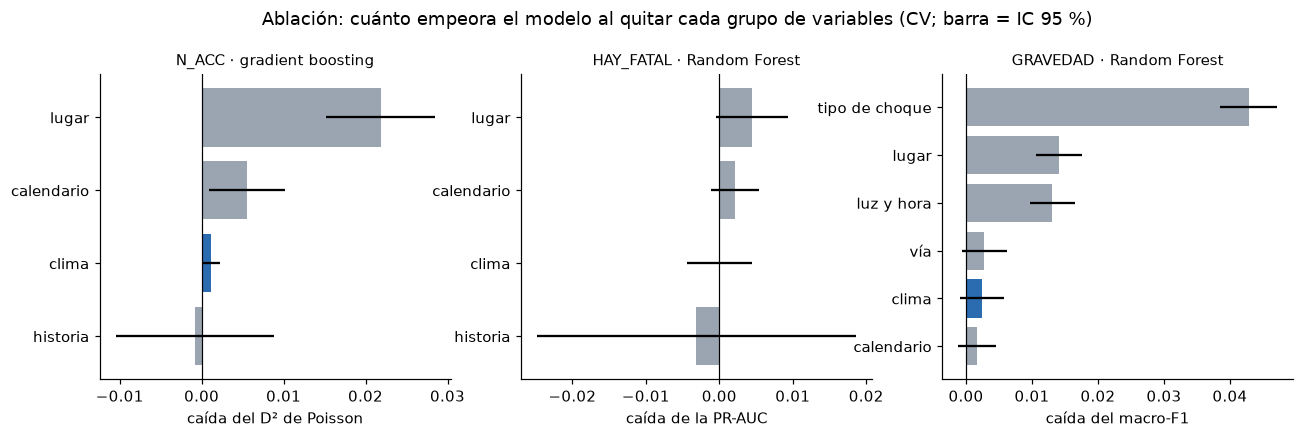

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
grafico(axs[0], abl_nacc, "N_ACC · gradient boosting", "caída del D² de Poisson")
grafico(axs[1], abl_fatal, "HAY_FATAL · Random Forest", "caída de la PR-AUC")
grafico(axs[2], abl_grav, "GRAVEDAD · Random Forest", "caída del macro-F1")
fig.suptitle("Ablación: cuánto empeora el modelo al quitar cada grupo de variables (CV; barra = IC 95 %)", y=1.04)
fig.savefig(PLOTS / "modelo_07_ablacion.png", bbox_inches="tight")
plt.show()

## 3. Importancia por permutación (holdout abr–sep 2021 y test 80/20)

N_ACC


,grupo,caida,desv
0,historia,0.2122,0.0082
1,lugar,0.1937,0.0072
2,clima,0.0006,0.0004
3,calendario,-0.0002,0.0001


HAY_FATAL


,grupo,caida,desv
0,historia,0.0825,0.0068
1,lugar,0.0022,0.0032
2,calendario,0.0003,0.0004
3,clima,-0.0020,0.0028


GRAVEDAD


,grupo,caida,desv
0,tipo de choque,0.0650,0.0047
1,lugar,0.0217,0.0052
2,vía,0.0089,0.0074
3,clima,-0.0036,0.0042
4,luz y hora,-0.0049,0.0073
5,calendario,-0.0051,0.0045


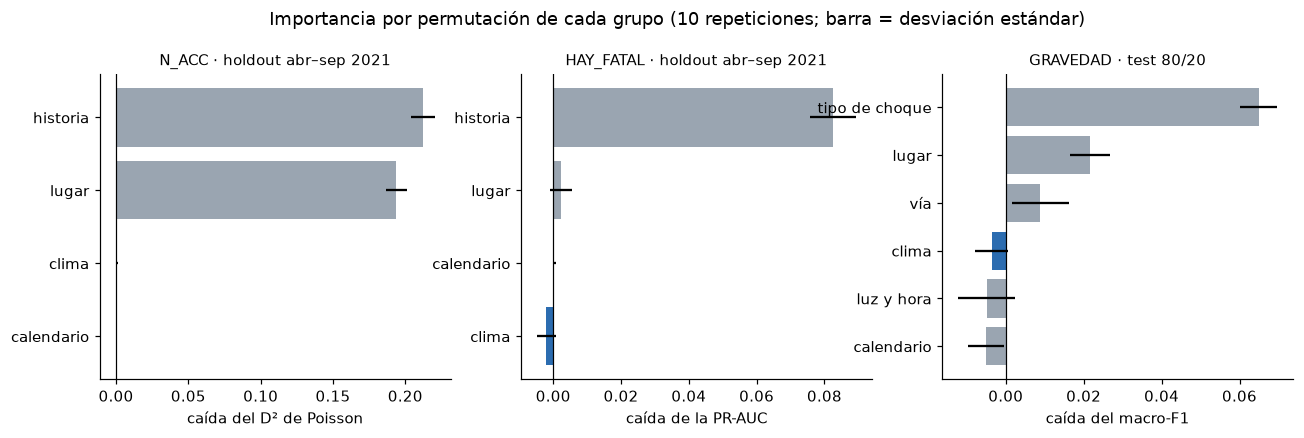

Tiempo total: 442 s


In [6]:
d2 = lambda y, m, X: E.metricas_conteo(y, m.predict(X))["d2_poisson"]
prauc = lambda y, m, X: E.metricas_binaria(y, m.predict_proba(X)[:, 1])["pr_auc"]
mf1 = lambda y, m, X: E.metricas_multiclase(y, m.predict_proba(X))["macro_f1"]

m_nacc = M.gbm_conteo(COLS1, **GBM_AJ["N_ACC"]).fit(tr1[X1], tr1.N_ACC)
m_fatal = M.random_forest(COLS1, **RF_AJ["HAY_FATAL"]).fit(tr1[X1], tr1.HAY_FATAL)
m_grav = M.random_forest(COLS2, **RF_AJ["GRAVEDAD"]).fit(tr2[X2], tr2.GRAVEDAD)

perm_nacc = permutacion_grupos(m_nacc, M.GRUPOS_T1, te1[X1], te1.N_ACC, d2)
perm_fatal = permutacion_grupos(m_fatal, M.GRUPOS_T1, te1[X1], te1.HAY_FATAL, prauc)
perm_grav = permutacion_grupos(m_grav, M.GRUPOS_T2, te2[X2], te2.GRAVEDAD, mf1)
for nombre, t in [("N_ACC", perm_nacc), ("HAY_FATAL", perm_fatal), ("GRAVEDAD", perm_grav)]:
    print(nombre); display(t.round(4))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
grafico(axs[0], perm_nacc, "N_ACC · holdout abr–sep 2021", "caída del D² de Poisson")
grafico(axs[1], perm_fatal, "HAY_FATAL · holdout abr–sep 2021", "caída de la PR-AUC")
grafico(axs[2], perm_grav, "GRAVEDAD · test 80/20", "caída del macro-F1")
fig.suptitle("Importancia por permutación de cada grupo (10 repeticiones; barra = desviación estándar)", y=1.04)
fig.savefig(PLOTS / "modelo_08_permutacion.png", bbox_inches="tight")
plt.show()
print(f"Tiempo total: {time.time() - t0:.0f} s")

## 4. Lectura

**La lluvia aporta poco, pero no cero.**
- `N_ACC`: quitar el clima baja el D² en 0.001 (IC ± 0.001; peor en 4 de 5 pliegues). Es una mejora real pero
  pequeña; la permutación lo confirma (0.0006).
- `HAY_FATAL`: el clima no aporta (caída 0.000 ± 0.004).
- `GRAVEDAD`: caída de 0.002 ± 0.003 (peor en 15 de 25 pliegues): no se distingue de cero.

**Qué sostiene la predicción:**
- Tarea 1: el **lugar** (departamento y altitud) es lo único cuya ablación cae en todos los pliegues (D² −0.022).
  La **historia** reciente es lo que más usa el modelo (permutación: D² −0.21, PR-AUC −0.08), pero quitarla no
  cambia la métrica: historia y lugar llevan la misma información (cuánto se accidenta cada departamento) y uno
  reemplaza al otro. Por eso hay que leer las dos medidas juntas.
- Tarea 2: el **tipo de choque** domina (macro-F1 −0.043, peor en 25 de 25), seguido del **lugar** y de **luz y
  hora**; vía, clima y calendario no se distinguen de cero.

**Respuesta a la pregunta del proyecto:** con las variables de lugar, historia y calendario, la lluvia del día añade
muy poca información al riesgo diario y casi ninguna a la gravedad. Coincide con el EDA (la relación con la lluvia es
débil y se solapa con la estación).